# 04 · Case studies

Three stories that show what disproportionality analysis can and cannot do:

1. **Montelukast and neuropsychiatric events**: a true signal that FAERS showed
   years before the 2020 boxed warning.
2. **Fluoroquinolones and aortic aneurysm**: a rare, serious reaction added to
   the levofloxacin label in 2019.
3. **Ranitidine and cancer**: a *false* signal created by litigation after the
   2019–2020 NDMA contamination recall (stimulated reporting).

Each chart replays the database quarter by quarter (only cases received by
then) and shows the lower bound of each method's estimate. The EBGM prior is
the one fitted on the full window, to keep the curves comparable.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import LogLocator

from faers import plotting as P
from faers.ebgm import Prior
from faers.temporal import replay_pair

DB = Path("../data/faers_warehouse.duckdb")
FIGURES = Path("../reports/figures")
con = duckdb.connect(str(DB), read_only=True)
prior = Prior(**con.execute("SELECT * FROM ebgm_prior").df().iloc[0].to_dict())
changes = pd.read_csv("../reports/tables/first_signals.csv", parse_dates=["label_date"])
changes = changes[changes.group == "label change"]
QUARTERS = pd.date_range("2014-09-30", "2026-06-30", freq="QE")

COLUMNS = {"PRR": "prr_lower", "ROR": "ror_lower", "BCPNN": "ic025", "EBGM": "eb05"}
THRESHOLDS = {"PRR": 1, "ROR": 1, "BCPNN": 0, "EBGM": 2}
P.apply_style()


def save(fig, name):
    P.save(fig, name, folder=FIGURES)


def first_crossing(history):
    """First quarter in which each lower bound is above its signal threshold."""
    out = {}
    for name, column in COLUMNS.items():
        above = history[history[column] > THRESHOLDS[name]]
        out[name] = above.quarter_end.min().date() if len(above) else None
    return out


def plot_pair(ax, drug, pt, event_date=None, event_label=None, labels=False, event_y=0.98):
    """Lower bound of every method over time (log scale), with the regulatory event marked."""
    history = replay_pair(con, drug, pt, QUARTERS, prior)
    series = {}
    for name, column in COLUMNS.items():
        values = history[column] if name != "BCPNN" else 2 ** history[column]
        ax.plot(history.quarter_end, values, color=P.METHOD_COLORS[name], label=name)
        series[name] = np.log10(values.to_numpy())
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    P.plain_log(ax)
    ax.axhline(1, color=P.MUTED, linewidth=0.8)
    ax.annotate("1 = no disproportionality", (history.quarter_end.iloc[-1], 1), xytext=(0, -5),
                textcoords="offset points", fontsize=8, color=P.MUTED, ha="right", va="top")
    if event_date is not None:
        ax.axvline(event_date, color=P.MUTED, linewidth=1, linestyle=(0, (4, 3)))
        ax.annotate(event_label, (event_date, event_y), xycoords=("data", "axes fraction"),
                    xytext=(-6, 0), textcoords="offset points", fontsize=8.5, color=P.MUTED,
                    ha="right", va="top")
    if labels:
        # End labels in log space: nudge apart in decades, then convert back.
        ends = sorted((v[-1], n) for n, v in series.items())
        placed = []
        for value, name in ends:
            target = value if not placed or value - placed[-1] >= 0.09 else placed[-1] + 0.09
            placed.append(target)
            ax.annotate(name, (history.quarter_end.iloc[-1], 10 ** target), xytext=(8, 0),
                        textcoords="offset points", va="center", fontsize=8.5,
                        fontweight="semibold", color=P.INK)
            ax.plot(history.quarter_end.iloc[-1], 10 ** value, "o", markersize=4.5,
                    color=P.METHOD_COLORS[name], clip_on=False, zorder=5)
    ax.set_ylabel("Lower bound of the estimate")
    return history

Note: the IC025 of BCPNN is on a log2 scale, so it is drawn as 2^IC025 to share
the ratio axis with the others. The horizontal line at 1 means "no
disproportionality"; each method's own signal threshold is listed below each chart.

## 1. Montelukast: neuropsychiatric events

In [2]:
montelukast = changes[changes.drug == "MONTELUKAST"].sort_values("label_date")
montelukast[["pt", "label_date", "section"]]

,pt,label_date,section
2959,tic,2016-12-13,5 Warnings and Precautions
2960,dysphemia,2019-08-09,6 Adverse Reactions
2961,depression,2020-04-29,Boxed Warning
2962,aggression,2020-04-29,Boxed Warning
2963,agitation,2020-04-29,Boxed Warning
2964,phenylketonuria,2021-02-22,5 Warnings and Precautions


,PRR,ROR,BCPNN,EBGM
suicidal ideation,2014-09-30,2014-09-30,2014-09-30,2014-09-30
aggression,2014-09-30,2014-09-30,2014-09-30,2014-09-30


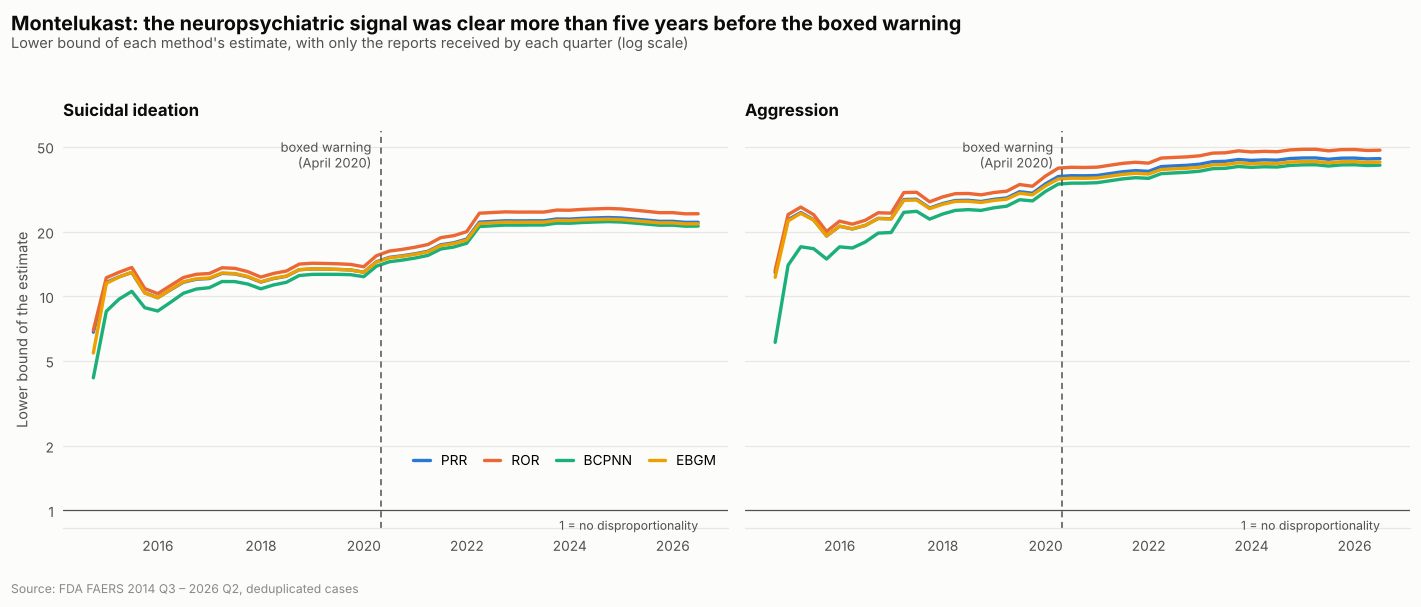

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
boxed = pd.Timestamp("2020-04-29")
crossings = {}
for ax, pt in zip(axes, ["suicidal ideation", "aggression"]):
    history = plot_pair(ax, "MONTELUKAST", pt, boxed, "boxed warning\n(April 2020)")
    crossings[pt] = first_crossing(history)
    ax.set_title(pt.capitalize(), fontsize=11, pad=10)
axes[1].set_ylabel("")
axes[0].legend(loc="lower right", ncol=4, handlelength=1.2, columnspacing=1.2, bbox_to_anchor=(1, 0.12))
fig.suptitle("Montelukast: the neuropsychiatric signal was clear more than five years before the boxed warning",
             x=0.01, y=1.06, ha="left", fontsize=13, fontweight="bold", color=P.INK)
fig.text(0.01, 0.99, "Lower bound of each method's estimate, with only the reports received by each quarter (log scale)",
         fontsize=9.5, color=P.MUTED, ha="left")
P.source_note(fig)
fig.tight_layout()
save(fig, "case_montelukast")
pd.DataFrame(crossings).T

## 2. Levofloxacin: aortic aneurysm

In [4]:
levo = changes[(changes.drug == "LEVOFLOXACIN") & changes.pt.str.contains("aneurysm")]
levo[["pt", "label_date", "section"]]

,pt,label_date,section
2557,aneurysm,2019-05-03,6 Adverse Reactions
2558,aortic aneurysm,2019-05-03,6 Adverse Reactions


{'PRR': datetime.date(2014, 9, 30), 'ROR': datetime.date(2014, 9, 30), 'BCPNN': datetime.date(2014, 9, 30), 'EBGM': datetime.date(2014, 9, 30)}


,quarter_end,a
0,2014-09-30,4
8,2016-09-30,14
16,2018-09-30,1692
24,2020-09-30,1736
47,2026-06-30,1745


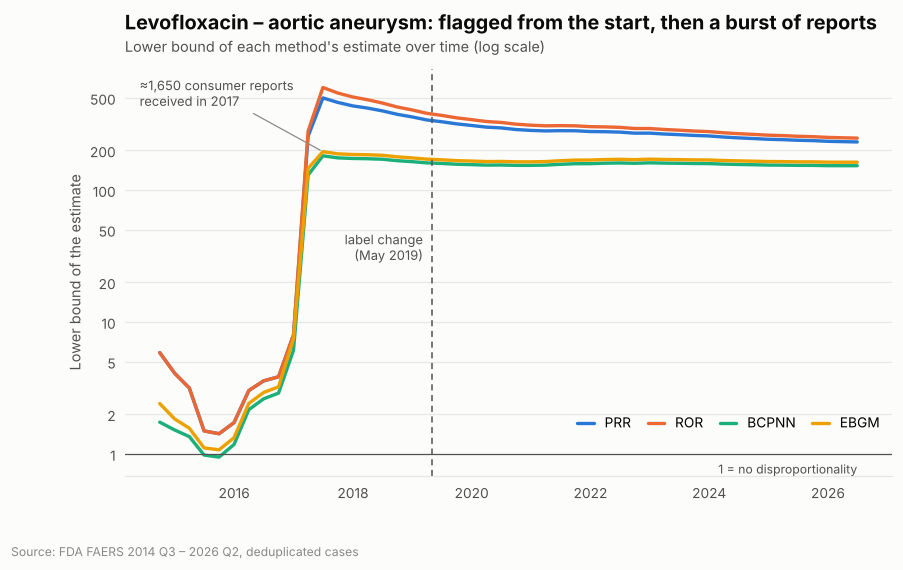

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
label_date = levo.label_date.min()
history = plot_pair(ax, "LEVOFLOXACIN", "aortic aneurysm", label_date, "label change\n(May 2019)", event_y=0.6)
ax.legend(loc="lower right", ncol=4, handlelength=1.2, columnspacing=1.2, bbox_to_anchor=(1, 0.08))
burst = history[history.quarter_end.dt.year == 2017]
ax.annotate("≈1,650 consumer reports\nreceived in 2017", (burst.quarter_end.iloc[1], burst.eb05.iloc[1]),
            xytext=(-120, 30), textcoords="offset points", fontsize=8.5, color=P.MUTED,
            arrowprops={"arrowstyle": "-", "color": P.FAINT, "linewidth": 0.8})
P.headline(ax, "Levofloxacin – aortic aneurysm: flagged from the start, then a burst of reports",
           "Lower bound of each method's estimate over time (log scale)")
P.source_note(fig)
save(fig, "case_levofloxacin")
print(first_crossing(history))
history[["quarter_end", "a"]].iloc[[0, 8, 16, 24, -1]]

## 3. Ranitidine: a false signal from stimulated reporting

{'PRR': datetime.date(2019, 12, 31), 'ROR': datetime.date(2019, 12, 31), 'BCPNN': datetime.date(2019, 12, 31), 'EBGM': datetime.date(2019, 12, 31)}


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
reporter,,,,,,,,,,,,,
Lawyer,0,0,0,0,3,37,34306,121557,26586,5840,50,7,1
Other reporters,303,851,991,779,1657,2057,18982,97865,90403,3042,203,84,18


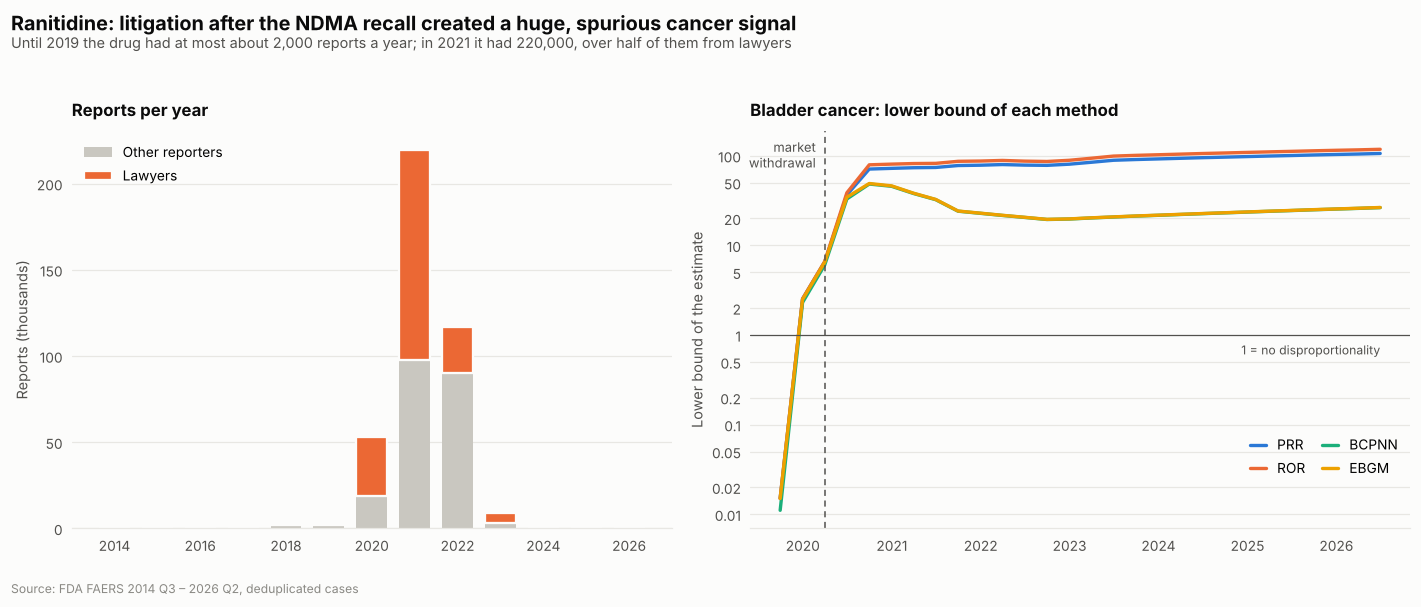

In [6]:
reporters = con.execute("""
    SELECT YEAR(r.init_fda_dt) AS year,
           CASE WHEN d.occp_cod = 'LW' THEN 'Lawyer' ELSE 'Other reporters' END AS reporter,
           COUNT(DISTINCT r.primaryid) AS reports
    FROM report_drug_event AS r JOIN demo_dedup AS d USING (primaryid)
    WHERE r.drug = 'RANITIDINE' AND r.init_fda_dt >= DATE '2014-01-01'
    GROUP BY ALL ORDER BY year
""").df().pivot(index="year", columns="reporter", values="reports").fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ax.bar(reporters.index, reporters["Other reporters"] / 1e3, color=P.NEUTRAL, width=0.72,
       label="Other reporters")
ax.bar(reporters.index, reporters["Lawyer"] / 1e3, bottom=reporters["Other reporters"] / 1e3,
       color=P.HIGHLIGHT, width=0.72, label="Lawyers", edgecolor=P.SURFACE, linewidth=1.5)
ax.set_ylabel("Reports (thousands)")
ax.legend(loc="upper left")
ax.set_title("Reports per year", fontsize=11, pad=10)
history = plot_pair(axes[1], "RANITIDINE", "bladder cancer", pd.Timestamp("2020-04-01"),
                    "market\nwithdrawal")
axes[1].set_title("Bladder cancer: lower bound of each method", fontsize=11, pad=10)
axes[1].legend(loc="lower right", ncol=2, handlelength=1.2, columnspacing=1.2, bbox_to_anchor=(1, 0.1))
fig.suptitle("Ranitidine: litigation after the NDMA recall created a huge, spurious cancer signal",
             x=0.01, y=1.06, ha="left", fontsize=13, fontweight="bold", color=P.INK)
fig.text(0.01, 0.99, "Until 2019 the drug had at most about 2,000 reports a year; in 2021 it had 220,000, over half of them from lawyers",
         fontsize=9.5, color=P.MUTED, ha="left")
P.source_note(fig)
fig.tight_layout()
save(fig, "case_ranitidine")
print(first_crossing(history))
reporters.astype(int).T

## Takeaways

- **Montelukast – neuropsychiatric events.** Suicidal ideation and aggression were already above every method's threshold at the very start of the window (2014), more than five years before the April 2020 boxed warning. The SrLC history shows that neuropsychiatric terms were being added to an existing warning since 2016 (tic in 2016, stuttering in 2019): the boxed warning was a regulatory escalation of a long-known signal, not a new discovery. Here all four methods agree completely.
- **Levofloxacin – aortic aneurysm.** The pair was flagged from the start with only 4 reports, but its count jumped from 14 to about 1,700 within 2017, almost all filed by consumers in a single year, two years before the May 2019 label change. A real safety issue can still reach FAERS as a burst of stimulated reports, which inflates every disproportionality score at once.
- **Ranitidine – cancer.** Before the 2019 NDMA contamination news the drug had a few hundred reports a year. After it, the drug received more than 50,000 reports in 2020 and 220,000 in 2021, over half of them from lawyers, and bladder cancer crossed every threshold at the end of 2019. All four methods "detect" it with huge scores: **disproportionality cannot tell a pharmacological signal from a reporting artefact**; only the context (reporter type, timing, media attention) can. Note how BCPNN and EBGM, whose expected count adapts to the flood of ranitidine reports, settle much lower than PRR and ROR.
